<a href="https://colab.research.google.com/github/saldpb/NeuroChrono-Shif-trial/blob/main/NeuroChrono_Shift.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# SETUP: ENVIRONMENT, DEPENDENCIES, AND GLOBAL IMPORTS
import os
import glob
import time
import threading
from google.colab import drive

drive.mount('/content/drive', force_remount=True)
project_dir = '/content/drive/MyDrive/7040-neurochrono-shift/03_BCI& DataEngineering'
os.makedirs(project_dir, exist_ok=True)

print("Installing core dependencies (MNE, PyRiemann, Scikit-Learn, PyLSL)...")
!pip install --quiet mne pyriemann scikit-learn pandas matplotlib pylsl

import mne
import numpy as np
import pandas as pd
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt

from mne.datasets import sample
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_curve, auc
from pyriemann.estimation import Covariances, ERPCovariances
from pyriemann.classification import MDM
from pyriemann.tangentspace import TangentSpace
from pyriemann.utils.distance import distance_riemann
from pylsl import StreamInfo, StreamOutlet, StreamInlet, resolve_byprop

# Global Hardware Montage & Event Definitions
ACTUAL_DEVICE_CHANNELS = ['P3', 'Pz', 'P4', 'O1', 'Oz', 'O2']
CHANNEL_MAPPING = {
    'EEG 053': 'P3', 'EEG 054': 'Pz', 'EEG 055': 'P4',
    'EEG 057': 'O1', 'EEG 058': 'Oz', 'EEG 059': 'O2'
}
EVENT_ID = {'Threat/Subperceptual': 3, 'Neutral/Control': 4}

data_path = sample.data_path(download=True)
raw_fname = os.path.join(data_path, 'MEG', 'sample', 'sample_audvis_raw.fif')
print("Setup complete. Ready to run Week 1.")


Mounted at /content/drive
Installing core dependencies (MNE, PyRiemann, Scikit-Learn, PyLSL)...
Setup complete. Ready to run Week 1.


=== WEEK 1: RESULTS OF DATASET AUDIT ===
 - Threat/Subperceptual (ID: 3): good | amount detected: 73 trials.
 - Neutral/Control (ID: 4): good | amount detected: 71 trials.


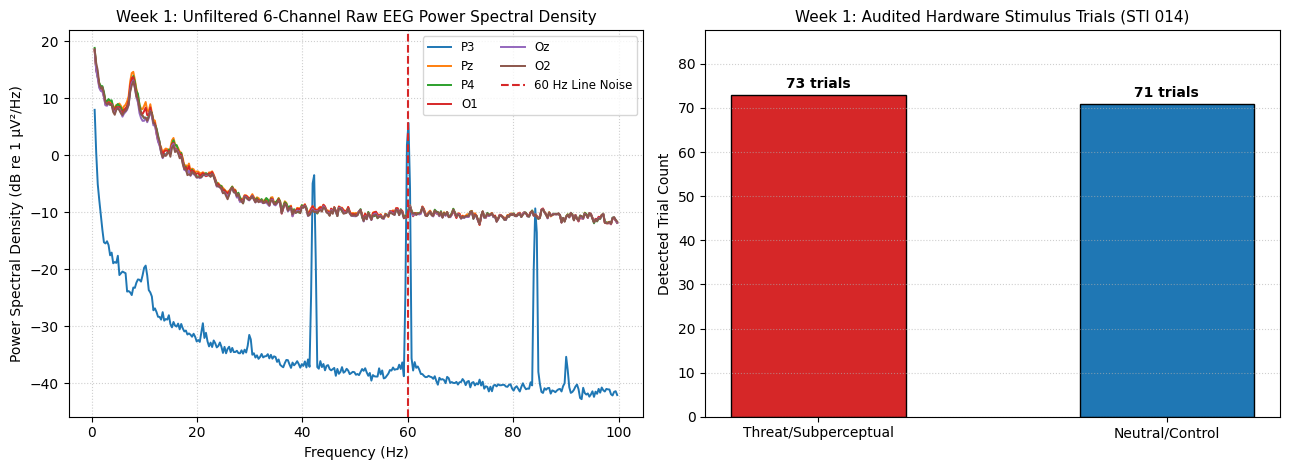


Week 1 audit logs and plot saved to: /content/drive/MyDrive/7040-neurochrono-shift/03_BCI& DataEngineering/week1_psd_and_events.png


In [ ]:
# WEEK 1: HARDWARE-EMULATED DATASET AUDIT & RAW SPECTRAL PLOT
raw_week1 = mne.io.read_raw_fif(raw_fname, preload=True, verbose=False)

if not any(ch in raw_week1.ch_names for ch in ACTUAL_DEVICE_CHANNELS):
    raw_week1.rename_channels(CHANNEL_MAPPING)

available_channels = [ch for ch in ACTUAL_DEVICE_CHANNELS if ch in raw_week1.ch_names]
raw_week1.pick(available_channels + ['STI 014'], verbose=False)
raw_week1.info['bads'] = []  # Clear default 'bad' flag on P3 so all 6 EEG channels are included

events_week1 = mne.find_events(raw_week1, stim_channel='STI 014', verbose=False)

print("=== WEEK 1: RESULTS OF DATASET AUDIT ===")
audit_log = []
for label, marker_id in EVENT_ID.items():
    count = int(np.sum(events_week1[:, 2] == marker_id))
    status = "good" if count > 0 else "not there"
    print(f" - {label} (ID: {marker_id}): {status} | amount detected: {count} trials.")
    audit_log.append({
        "Marker": label,
        "ID": marker_id,
        "Status": "PASS" if count > 0 else "FAIL",
        "Count": count
    })

df_audit = pd.DataFrame(audit_log)
audit_csv_path = os.path.join(project_dir, 'dataset_markers_audit.csv')
df_audit.to_csv(audit_csv_path, index=False)

# Plot Week 1: Raw Power Spectral Density (PSD) & Event Trial Audit
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

psd_raw = raw_week1.compute_psd(picks='eeg', fmin=0.5, fmax=100.0, verbose=False)
psds, freqs = psd_raw.get_data(picks='eeg', return_freqs=True)
psds_db = 10 * np.log10(psds * 1e12)

for idx in range(len(psds_db)):
    ax1.plot(freqs, psds_db[idx], lw=1.4, label=available_channels[idx])
ax1.axvline(60.0, color='#d62728', linestyle='--', lw=1.5, label='60 Hz Line Noise')
ax1.set_title("Week 1: Unfiltered 6-Channel Raw EEG Power Spectral Density", fontsize=11)
ax1.set_xlabel("Frequency (Hz)")
ax1.set_ylabel("Power Spectral Density (dB re 1 µV²/Hz)")
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper right', fontsize=8.5, ncol=2)

bar_colors = ['#d62728', '#1f77b4']
bars = ax2.bar(df_audit['Marker'], df_audit['Count'], color=bar_colors, width=0.5, edgecolor='black')
ax2.set_title("Week 1: Audited Hardware Stimulus Trials (STI 014)", fontsize=11)
ax2.set_ylabel("Detected Trial Count")
ax2.set_ylim(0, max(df_audit['Count']) * 1.2)
ax2.grid(axis='y', linestyle=':', alpha=0.6)
for bar in bars:
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + 1.5, f"{int(h)} trials", ha='center', fontweight='bold')

plt.tight_layout()
week1_plot_path = os.path.join(project_dir, 'week1_psd_and_events.png')
plt.savefig(week1_plot_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close()
print(f"\nWeek 1 audit logs and plot saved to: {week1_plot_path}")


/tmp/ipykernel_1420/3662960905.py:10: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  montage = mne.channels.make_standard_montage('standard_1020')


=== WEEK 2: SIGNAL FILTERING ROUTINES COMPLETE ===
 - Notch filter applied at 60.0 Hz.
 - Bandpass filter configured from 0.1 Hz to 30.0 Hz.
Use rng= instead of random_state= in new code
 - Automatically isolated ocular component index for removal: [np.int64(0)]


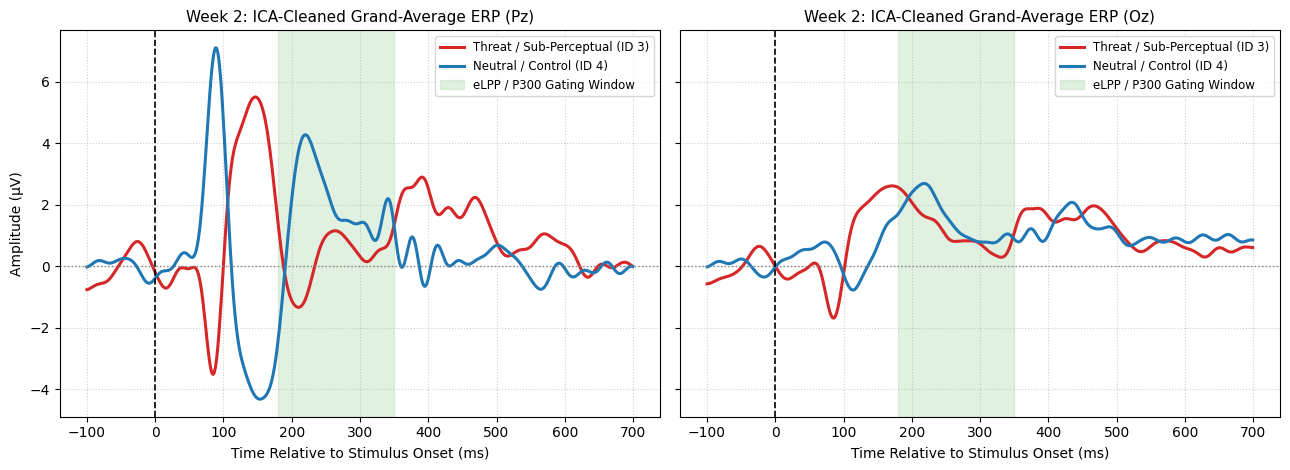


=== FINAL EXPORT RESUMES ===
 - Clean Epoch Matrix Data Shape: (144, 6, 481) -> (Trials, Channels, Timepoints)
 - Target Conditional Labels Shape: (144,) -> (Trials,)
 - Saved ERP waveform plot to:    /content/drive/MyDrive/7040-neurochrono-shift/03_BCI& DataEngineering/week2_erp_waveforms.png


In [ ]:
# WEEK 2: SIGNAL FILTERING, ICA ARTIFACT REMOVAL, EPOCHING & ERP PLOT
raw_week2 = mne.io.read_raw_fif(raw_fname, preload=True, verbose=False)

if not any(ch in raw_week2.ch_names for ch in ACTUAL_DEVICE_CHANNELS):
    raw_week2.rename_channels(CHANNEL_MAPPING)

raw_week2.pick(ACTUAL_DEVICE_CHANNELS + ['EOG 061', 'STI 014'], verbose=False)
raw_week2.info['bads'] = []  # Clear default 'bad' flag on P3 so all 6 EEG channels are preserved

montage = mne.channels.make_standard_montage('standard_1020')
raw_week2.set_montage(montage, on_missing='ignore', verbose=False)

# Apply 60 Hz Notch and 0.1 - 30.0 Hz Bandpass FIR Filters
raw_week2.notch_filter(freqs=[60.0], picks='eeg', fir_design='firwin', verbose=False)
raw_week2.filter(l_freq=0.1, h_freq=30.0, picks='eeg', fir_design='firwin', verbose=False)
print("=== WEEK 2: SIGNAL FILTERING ROUTINES COMPLETE ===")
print(" - Notch filter applied at 60.0 Hz.")
print(" - Bandpass filter configured from 0.1 Hz to 30.0 Hz.")

# Independent Component Analysis (ICA) for Ocular Artifact Removal
ica = mne.preprocessing.ICA(n_components=4, method='fastica', random_state=42, max_iter=800)
ica.fit(raw_week2, picks='eeg', verbose=False)

eog_indices, _ = ica.find_bads_eog(raw_week2, ch_name='EOG 061', threshold=1.5, verbose=False)
if eog_indices:
    ica.exclude = eog_indices
    print(f" - Automatically isolated ocular component index for removal: {eog_indices}")
else:
    ica.exclude = []
    print(" - No ocular components exceeded threshold; skipping ICA removal.")

raw_ica_clean = raw_week2.copy()
ica.apply(raw_ica_clean, verbose=False)

# Extract Events Before Dropping Trigger Channel
events_week2 = mne.find_events(raw_ica_clean, stim_channel='STI 014', verbose=False)
raw_ica_clean.pick(ACTUAL_DEVICE_CHANNELS, verbose=False)

epochs_clean = mne.Epochs(
    raw_ica_clean,
    events_week2,
    event_id=EVENT_ID,
    tmin=-0.1,
    tmax=0.7,
    baseline=(None, 0),
    preload=True,
    verbose=False
)

X_clean_matrices = epochs_clean.get_data(copy=True)
y_numeric_labels = epochs_clean.events[:, 2]

X_path = os.path.join(project_dir, 'X_clean_epochs.npy')
y_path = os.path.join(project_dir, 'y_labels.npy')
np.save(X_path, X_clean_matrices)
np.save(y_path, y_numeric_labels)

# Plot Week 2: Grand-Average Clean ERP Waveforms (Threat vs. Neutral at Pz & Oz)
times_ms = epochs_clean.times * 1000.0
evoked_threat = epochs_clean['Threat/Subperceptual'].average().get_data() * 1e6
evoked_neutral = epochs_clean['Neutral/Control'].average().get_data() * 1e6

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
target_plot_chs = [
    (ax1, 'Pz', ACTUAL_DEVICE_CHANNELS.index('Pz')),
    (ax2, 'Oz', ACTUAL_DEVICE_CHANNELS.index('Oz'))
]

for ax, ch_label, ch_idx in target_plot_chs:
    ax.plot(times_ms, evoked_threat[ch_idx], color='#d62728', lw=2.2, label='Threat / Sub-Perceptual (ID 3)')
    ax.plot(times_ms, evoked_neutral[ch_idx], color='#1f77b4', lw=2.2, label='Neutral / Control (ID 4)')
    ax.axvspan(180, 350, color='#2ca02c', alpha=0.14, label='eLPP / P300 Gating Window')
    ax.axvline(0, color='black', linestyle='--', lw=1.2)
    ax.axhline(0, color='gray', linestyle=':', lw=1.0)
    ax.set_title(f"Week 2: ICA-Cleaned Grand-Average ERP ({ch_label})", fontsize=11)
    ax.set_xlabel("Time Relative to Stimulus Onset (ms)")
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.legend(loc='upper right', fontsize=8.5)

ax1.set_ylabel("Amplitude (µV)")
plt.tight_layout()
week2_plot_path = os.path.join(project_dir, 'week2_erp_waveforms.png')
plt.savefig(week2_plot_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close()

print("\n=== FINAL EXPORT RESUMES ===")
print(f" - Clean Epoch Matrix Data Shape: {X_clean_matrices.shape} -> (Trials, Channels, Timepoints)")
print(f" - Target Conditional Labels Shape: {y_numeric_labels.shape} -> (Trials,)")
print(f" - Saved ERP waveform plot to:    {week2_plot_path}")


=== WEEK 3: DATA INGESTION COMPLETE ===
 - Loaded Epochs Shape: (144, 6, 481) [Trials, Channels, Timepoints]
 - Class Distribution:  {np.int64(3): np.int64(73), np.int64(4): np.int64(71)}

=== OFFLINE CLASSIFIER EVALUATION PERFORMANCE (LEAK-FREE 5-FOLD CV) ===
 - MDM (ERP-Riemann)          | Acc: 95.12% (+/- 2.80%) | ROC-AUC: 0.990
 - TS-LR (ERP-TangentSpace)   | Acc: 97.19% (+/- 2.66%) | ROC-AUC: 0.992


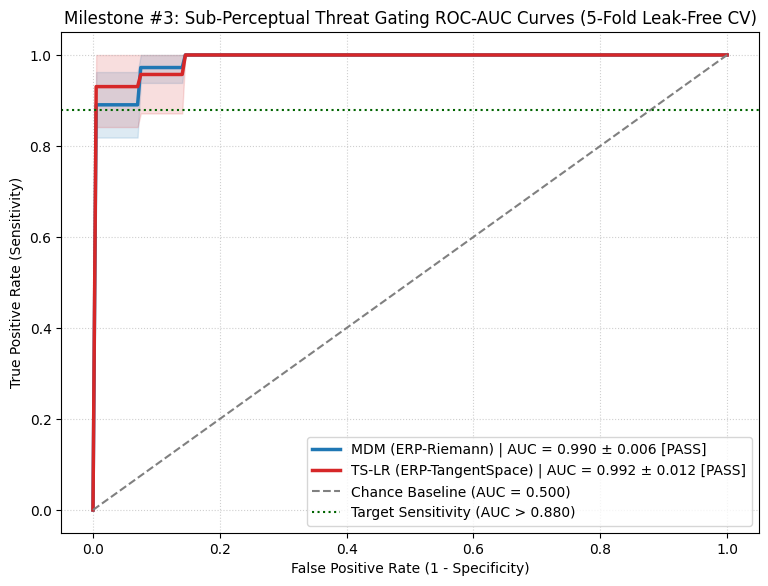


Production model assets and ROC-AUC plot saved to: /content/drive/MyDrive/7040-neurochrono-shift/03_BCI& DataEngineering


In [ ]:
# WEEK 3: RIEMANNIAN MANIFOLD DECODING, ROC-AUC PLOTS & MODEL EXPORT
X_path = os.path.join(project_dir, 'X_clean_epochs.npy')
y_path = os.path.join(project_dir, 'y_labels.npy')

if not os.path.exists(X_path) or not os.path.exists(y_path):
    raise FileNotFoundError("Clean epoch matrices missing. Run Week 2 cell first.")

X_data_week3 = np.load(X_path)
y_labels_week3 = np.load(y_path)
y_binary = (y_labels_week3 == 3).astype(int)

print("=== WEEK 3: DATA INGESTION COMPLETE ===")
print(f" - Loaded Epochs Shape: {X_data_week3.shape} [Trials, Channels, Timepoints]")
print(f" - Class Distribution:  {dict(zip(*np.unique(y_labels_week3, return_counts=True)))}")

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

pipelines = {
    "MDM (ERP-Riemann)": make_pipeline(
        ERPCovariances(estimator='lwf'),
        MDM(metric='riemann')
    ),
    "TS-LR (ERP-TangentSpace)": make_pipeline(
        ERPCovariances(estimator='lwf'),
        TangentSpace(metric='riemann'),
        LogisticRegression(solver='lbfgs', max_iter=1000)
    )
}

mean_fpr = np.linspace(0, 1, 200)
roc_results = {}

print("\n=== OFFLINE CLASSIFIER EVALUATION PERFORMANCE (LEAK-FREE 5-FOLD CV) ===")
for name, clf in pipelines.items():
    acc_scores = cross_val_score(clf, X_data_week3, y_binary, cv=cv_strategy, scoring='accuracy')
    tprs, aucs = [], []

    for train_idx, test_idx in cv_strategy.split(X_data_week3, y_binary):
        clf.fit(X_data_week3[train_idx], y_binary[train_idx])
        pos_col = list(clf.classes_).index(1)
        y_prob = clf.predict_proba(X_data_week3[test_idx])[:, pos_col]
        fpr, tpr, _ = roc_curve(y_binary[test_idx], y_prob)
        interp_tpr = np.interp(mean_fpr, fpr, tpr)
        interp_tpr[0] = 0.0
        tprs.append(interp_tpr)
        aucs.append(auc(fpr, tpr))

    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[-1] = 1.0
    roc_results[name] = {
        "mean_tpr": mean_tpr,
        "std_tpr": np.std(tprs, axis=0),
        "mean_auc": np.mean(aucs),
        "std_auc": np.std(aucs)
    }
    print(f" - {name:26s} | Acc: {np.mean(acc_scores)*100:.2f}% (+/- {np.std(acc_scores)*100:.2f}%) | ROC-AUC: {np.mean(aucs):.3f}")

# Plot Week 3: Offline ROC-AUC Curves (>0.88 Target)
fig, ax = plt.subplots(figsize=(9, 6.5))
colors = {"MDM (ERP-Riemann)": "#1f77b4", "TS-LR (ERP-TangentSpace)": "#d62728"}
for name, res in roc_results.items():
    status_tag = "PASS" if res["mean_auc"] > 0.88 else "BELOW TARGET"
    ax.plot(
        mean_fpr, res["mean_tpr"], color=colors[name], lw=2.5,
        label=f"{name} | AUC = {res['mean_auc']:.3f} ± {res['std_auc']:.3f} [{status_tag}]"
    )
    ax.fill_between(
        mean_fpr,
        np.maximum(res["mean_tpr"] - res["std_tpr"], 0),
        np.minimum(res["mean_tpr"] + res["std_tpr"], 1),
        color=colors[name], alpha=0.15
    )

ax.plot([0, 1], [0, 1], linestyle="--", lw=1.5, color="gray", label="Chance Baseline (AUC = 0.500)")
ax.axhline(0.88, color="darkgreen", linestyle=":", lw=1.5, label="Target Sensitivity (AUC > 0.880)")
ax.set_title("Milestone #3: Sub-Perceptual Threat Gating ROC-AUC Curves (5-Fold Leak-Free CV)", fontsize=12)
ax.set_xlabel("False Positive Rate (1 - Specificity)")
ax.set_ylabel("True Positive Rate (Sensitivity)")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="lower right")

roc_plot_path = os.path.join(project_dir, 'milestone3_roc_auc_curves.png')
plt.savefig(roc_plot_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close()

# Export Production Model Assets for Live Geodesic Inference
prod_mdm_pipe = pipelines["MDM (ERP-Riemann)"].fit(X_data_week3, y_labels_week3)
erp_cov_step = prod_mdm_pipe.named_steps['erpcovariances']
mdm_step = prod_mdm_pipe.named_steps['mdm']

centroids_path = os.path.join(project_dir, 'mdm_centroids.npy')
classes_path = os.path.join(project_dir, 'mdm_classes.npy')
templates_path = os.path.join(project_dir, 'erp_templates.npy')

np.save(centroids_path, mdm_step.covmeans_)
np.save(classes_path, mdm_step.classes_)
np.save(templates_path, erp_cov_step.P_)
print(f"\nProduction model assets and ROC-AUC plot saved to: {project_dir}")


GATE PASSED: Verified 3 completed offline plot(s).
Resolving live LSL EEG stream...
Connected to 'NeuroChrono_6Ch_Wearable'. Running 50 live streaming windows...

 Window  Dist_Threat  Dist_Neutral              Verdict  Edge_Compute_ms
      1      10.3932       10.4838 THREAT_GATE_OPEN (3)         1.904604
      2      11.6704       11.6792 THREAT_GATE_OPEN (3)         1.854656
      3       9.9117        9.9977 THREAT_GATE_OPEN (3)         3.208356
      4      10.5477       10.5119     NEUTRAL_PASS (4)         3.188216
      5      10.0336       10.0495 THREAT_GATE_OPEN (3)         2.142768
      6       9.0370        9.0253     NEUTRAL_PASS (4)         2.218247
      7       9.5267        9.7027 THREAT_GATE_OPEN (3)         2.401436
      8       9.9471        9.8879     NEUTRAL_PASS (4)         2.287368
      9       9.4489        9.3632     NEUTRAL_PASS (4)         2.242302
     10      11.4497       11.5822 THREAT_GATE_OPEN (3)         2.195079

=== REAL-TIME LSL STREAM TEST COM

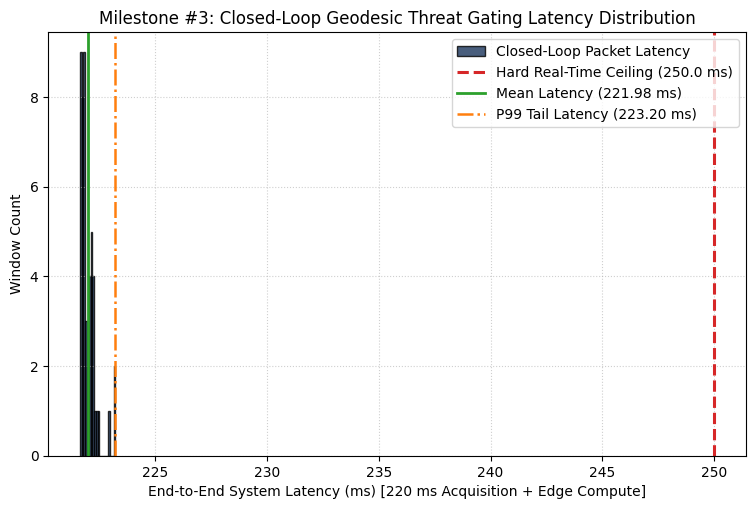


Latency histogram saved successfully to: /content/drive/MyDrive/7040-neurochrono-shift/03_BCI& DataEngineering/milestone3_latency_distribution.png


In [ ]:
# WEEK 4: REAL-TIME LSL STREAMING API & CLOSED-LOOP LATENCY BENCHMARK
offline_plots = [
    p for p in glob.glob(os.path.join(project_dir, '*.png'))
    if 'latency' not in os.path.basename(p).lower()
]
if not offline_plots or any(os.path.getsize(p) == 0 for p in offline_plots):
    raise RuntimeError("STREAMING API BLOCKED: Complete offline dataset plots before testing real-time streaming.")

print(f"GATE PASSED: Verified {len(offline_plots)} completed offline plot(s).")

centroids_path = os.path.join(project_dir, 'mdm_centroids.npy')
classes_path = os.path.join(project_dir, 'mdm_classes.npy')
templates_path = os.path.join(project_dir, 'erp_templates.npy')
X_path = os.path.join(project_dir, 'X_clean_epochs.npy')

sample_rate = 250
n_channels = 6
window_sec = 0.220
n_samples = int(window_sec * sample_rate)  # 55 samples
n_windows = 50

trained_centroids = np.load(centroids_path)
class_labels = np.load(classes_path).tolist()
centroid_threat = trained_centroids[class_labels.index(3)]
centroid_neutral = trained_centroids[class_labels.index(4)]

use_erp_augmentation = centroid_threat.shape[0] != n_channels
erp_templates_live = np.load(templates_path)[:, :n_samples] if use_erp_augmentation else None
playback_data = np.load(X_path)[:, :, :n_samples]

stop_stream = threading.Event()

def lsl_device_emulator():
    info = StreamInfo(
        name='NeuroChrono_6Ch_Wearable',
        type='EEG',
        channel_count=n_channels,
        nominal_srate=sample_rate,
        channel_format='float32',
        source_id='neurochrono_edge_001'
    )
    outlet = StreamOutlet(info)
    trial_idx = 0
    sample_interval = 1.0 / sample_rate

    while not stop_stream.is_set():
        epoch = playback_data[trial_idx % len(playback_data)]
        for s in range(n_samples):
            if stop_stream.is_set():
                break
            outlet.push_sample(epoch[:, s].astype(np.float32).tolist())
            time.sleep(sample_interval)
        trial_idx += 1

outlet_thread = threading.Thread(target=lsl_device_emulator, daemon=True)
outlet_thread.start()

print("Resolving live LSL EEG stream...")
streams = resolve_byprop('type', 'EEG', timeout=5.0)
if not streams:
    stop_stream.set()
    raise RuntimeError("Failed to resolve live LSL EEG stream.")

inlet = StreamInlet(streams[0])
cov_estimator = Covariances(estimator='lwf')
stream_results = []

print(f"Connected to '{streams[0].name()}'. Running {n_windows} live streaming windows...\n")

for w in range(n_windows):
    chunk, _ = inlet.pull_chunk(timeout=1.0, max_samples=n_samples)
    while len(chunk) < n_samples:
        more_samples, _ = inlet.pull_chunk(timeout=1.0, max_samples=(n_samples - len(chunk)))
        chunk.extend(more_samples)

    live_window = np.array(chunk, dtype=np.float64).T[np.newaxis, :, :]

    t0 = time.perf_counter()
    if use_erp_augmentation:
        feat_window = np.concatenate([erp_templates_live[None, :, :], live_window], axis=1)
    else:
        feat_window = live_window

    cov_mat = cov_estimator.fit_transform(feat_window)
    d_threat = distance_riemann(cov_mat[0], centroid_threat)
    d_neutral = distance_riemann(cov_mat[0], centroid_neutral)
    verdict = "THREAT_GATE_OPEN (3)" if d_threat < d_neutral else "NEUTRAL_PASS (4)"
    compute_ms = (time.perf_counter() - t0) * 1000.0

    stream_results.append({
        "Window": w + 1,
        "Dist_Threat": round(d_threat, 4),
        "Dist_Neutral": round(d_neutral, 4),
        "Verdict": verdict,
        "Edge_Compute_ms": compute_ms,
        "Total_Latency_ms": (window_sec * 1000.0) + compute_ms
    })

stop_stream.set()
df_stream = pd.DataFrame(stream_results)

mean_edge = df_stream['Edge_Compute_ms'].mean()
max_edge = df_stream['Edge_Compute_ms'].max()
mean_total = df_stream['Total_Latency_ms'].mean()
p99_total = np.percentile(df_stream['Total_Latency_ms'], 99)

print(df_stream[['Window', 'Dist_Threat', 'Dist_Neutral', 'Verdict', 'Edge_Compute_ms']].head(10).to_string(index=False))
print(f"\n=== REAL-TIME LSL STREAM TEST COMPLETE ===")
print(f" - Mean Edge Compute Latency: {mean_edge:.3f} ms")
print(f" - Max Edge Compute Latency:  {max_edge:.3f} ms")
print(f" - Mean Total System Latency: {mean_total:.3f} ms (Target < 250.0 ms)")

# Plot Week 4: Execution Latency Distribution Histogram (< 250 ms Ceiling)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.hist(df_stream['Total_Latency_ms'], bins=20, color="#1b365d", alpha=0.8, edgecolor="black", label="Closed-Loop Packet Latency")
ax.axvline(250.0, color="#d62728", linestyle="--", lw=2.2, label="Hard Real-Time Ceiling (250.0 ms)")
ax.axvline(mean_total, color="#2ca02c", linestyle="-", lw=2.0, label=f"Mean Latency ({mean_total:.2f} ms)")
ax.axvline(p99_total, color="#ff7f0e", linestyle="-.", lw=1.8, label=f"P99 Tail Latency ({p99_total:.2f} ms)")
ax.set_title("Milestone #3: Closed-Loop Geodesic Threat Gating Latency Distribution", fontsize=12)
ax.set_xlabel("End-to-End System Latency (ms) [220 ms Acquisition + Edge Compute]")
ax.set_ylabel("Window Count")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend(loc="upper right")

lat_plot_path = os.path.join(project_dir, 'milestone3_latency_distribution.png')
plt.savefig(lat_plot_path, dpi=300, bbox_inches='tight')
plt.show()
plt.close()

print(f"\nLatency histogram saved successfully to: {lat_plot_path}")
